<a href="https://colab.research.google.com/github/anupbagale/Neural_Network_lab/blob/main/Neural_network_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# McCulloch–Pitts model

In [1]:
"""
Title: Implementation of Logic Gates using Perceptron Model (Python + NumPy)

Description:
This program implements basic logic gates (AND, OR, NOT, NAND, NOR, XOR)
using a perceptron-like approach. Each gate computes a weighted sum of inputs
and applies a threshold activation function.

Note:
- AND, OR, NOT, NAND, NOR → Single-layer perceptron
- XOR → Multi-layer perceptron (since XOR is not linearly separable)
"""

import numpy as np


# ---------------------- AND GATE ----------------------
def and_gate(x1, x2):
    x = [x1, x2]          # Inputs
    w = [1, 1]            # Weights
    net = np.sum(np.multiply(x, w))  # Weighted sum

    # Threshold activation function
    if net >= 2:
        op = 1
    else:
        op = 0

    print('AND Gate -> x1 =', x[0], 'x2 =', x[1], 'Output =', op)


# Testing AND gate
for i1 in range(2):
    for i2 in range(2):
        and_gate(i1, i2)


# ---------------------- OR GATE ----------------------
def or_gate(x1, x2):
    x = [x1, x2]
    w = [1, 1]
    net = np.sum(np.multiply(x, w))

    if net >= 1:
        op = 1
    else:
        op = 0

    print('OR Gate  -> x1 =', x[0], 'x2 =', x[1], 'Output =', op)


# Testing OR gate
for i1 in range(2):
    for i2 in range(2):
        or_gate(i1, i2)


# ---------------------- NOT GATE ----------------------
def not_gate(x1):
    x = [x1]
    w = [1]
    net = np.sum(np.multiply(x, w))

    # Inverted threshold logic
    if net >= 1:
        op = 0
    else:
        op = 1

    print('NOT Gate -> x1 =', x[0], 'Output =', op)


# Testing NOT gate
for i1 in range(2):
    not_gate(i1)


# ---------------------- NAND GATE ----------------------
def nand_gate(x1, x2):
    x = [x1, x2]
    w = [1, 1]
    net = np.sum(np.multiply(x, w))

    # Opposite of AND gate
    if net >= 2:
        op = 0
    else:
        op = 1

    print('NAND Gate-> x1 =', x[0], 'x2 =', x[1], 'Output =', op)


# Testing NAND gate
for i1 in range(2):
    for i2 in range(2):
        nand_gate(i1, i2)


# ---------------------- NOR GATE ----------------------
def nor_gate(x1, x2):
    x = [x1, x2]
    w = [1, 1]
    net = np.sum(np.multiply(x, w))

    # Opposite of OR gate
    if net >= 1:
        op = 0
    else:
        op = 1

    print('NOR Gate -> x1 =', x[0], 'x2 =', x[1], 'Output =', op)


# Testing NOR gate (FIXED: previously OR was called by mistake)
for i1 in range(2):
    for i2 in range(2):
        nor_gate(i1, i2)


# ---------------------- XOR (EXOR) GATE ----------------------
def exor_gate(x1, x2):
    x = [x1, x2]

    # First layer weights (two neurons)
    w1 = [1, -1]
    w2 = [-1, 1]

    # Second layer weights
    w3 = [1, 1]

    # First neuron
    t1 = np.sum(np.multiply(x, w1))
    if t1 >= 1:
        net1 = 1
    else:
        net1 = 0

    # Second neuron
    t2 = np.sum(np.multiply(x, w2))
    if t2 >= 1:
        net2 = 1
    else:
        net2 = 0

    # Combine outputs of first layer
    net12 = [net1, net2]

    # Final output neuron
    net3 = np.sum(np.multiply(net12, w3))
    if net3 >= 1:
        op = 1
    else:
        op = 0

    print('XOR Gate -> x1 =', x[0], 'x2 =', x[1], 'Output =', op)


# Testing XOR gate
for i1 in range(2):
    for i2 in range(2):
        exor_gate(i1, i2)

AND Gate -> x1 = 0 x2 = 0 Output = 0
AND Gate -> x1 = 0 x2 = 1 Output = 0
AND Gate -> x1 = 1 x2 = 0 Output = 0
AND Gate -> x1 = 1 x2 = 1 Output = 1
OR Gate  -> x1 = 0 x2 = 0 Output = 0
OR Gate  -> x1 = 0 x2 = 1 Output = 1
OR Gate  -> x1 = 1 x2 = 0 Output = 1
OR Gate  -> x1 = 1 x2 = 1 Output = 1
NOT Gate -> x1 = 0 Output = 1
NOT Gate -> x1 = 1 Output = 0
NAND Gate-> x1 = 0 x2 = 0 Output = 1
NAND Gate-> x1 = 0 x2 = 1 Output = 1
NAND Gate-> x1 = 1 x2 = 0 Output = 1
NAND Gate-> x1 = 1 x2 = 1 Output = 0
NOR Gate -> x1 = 0 x2 = 0 Output = 1
NOR Gate -> x1 = 0 x2 = 1 Output = 0
NOR Gate -> x1 = 1 x2 = 0 Output = 0
NOR Gate -> x1 = 1 x2 = 1 Output = 0
XOR Gate -> x1 = 0 x2 = 0 Output = 0
XOR Gate -> x1 = 0 x2 = 1 Output = 1
XOR Gate -> x1 = 1 x2 = 0 Output = 1
XOR Gate -> x1 = 1 x2 = 1 Output = 0


# Habbian method

In [2]:
"""
Title: Hebbian Learning Implementation using Signum Activation (Python + NumPy)

Description:
This program demonstrates Hebbian Learning, an unsupervised learning rule.
The weights are updated using the formula:

    w_new = w_old + c * x * y

where:
- w = weight vector
- x = input vector
- y = output (from signum activation)
- c = learning rate

The model updates weights sequentially for multiple input samples.
"""

import numpy as np


# ---------------------- INITIAL WEIGHTS ----------------------
q = np.array([1, -1, 0, 0.5])   # Initial weight vector
print('Initial weights:', q)

# Transpose of weight vector (used for dot product)
w = np.transpose(q)
print('After transpose:', w)


# ---------------------- LEARNING RATE ----------------------
c = 1   # Learning rate (controls how much weights are updated)


# ---------------------- INPUT VECTORS ----------------------
x1 = np.array([1, -2, 1.5, 0])
x2 = np.array([1, -0.5, -2, -1.5])
x3 = np.array([0, 1, -1, 1.5])


# ---------------------- SIGNUM ACTIVATION FUNCTION ----------------------
def signum(x):
    """
    Signum function:
    Returns:
    1  -> if x > 0
    0  -> if x = 0
    -1 -> if x < 0
    """
    return np.sign(x)


# ---------------------- HEBBIAN LEARNING PROCESS ----------------------

# ---- Step 1: Process input x1 ----
net1 = np.dot(w, x1)        # Compute weighted sum (net input)
o1 = signum(net1)           # Compute output using activation function

dw = c * o1 * x1            # Hebbian weight update (Δw = c * x * y)
w = w + dw                  # Update weights

print("\nAfter x1 update:")
print("Net1:", net1, "Output:", o1)
print("Updated weights:", w)


# ---- Step 2: Process input x2 ----
net2 = np.dot(w, x2)
o2 = signum(net2)

dw = c * o2 * x2
w = w + dw

print("\nAfter x2 update:")
print("Net2:", net2, "Output:", o2)
print("Updated weights:", w)


# ---- Step 3: Process input x3 ----
net3 = np.dot(w, x3)
o3 = signum(net3)

dw = c * o3 * x3
w = w + dw

print("\nAfter x3 update:")
print("Net3:", net3, "Output:", o3)
print("Final weights:", w)

Initial weights: [ 1.  -1.   0.   0.5]
After transpose: [ 1.  -1.   0.   0.5]

After x1 update:
Net1: 3.0 Output: 1.0
Updated weights: [ 2.  -3.   1.5  0.5]

After x2 update:
Net2: -0.25 Output: -1.0
Updated weights: [ 1.  -2.5  3.5  2. ]

After x3 update:
Net3: -3.0 Output: -1.0
Final weights: [ 1.  -3.5  4.5  0.5]


#Perceptron method

In [3]:
"""
Title: Perceptron Learning Rule Implementation (Supervised Learning)

Description:
This program demonstrates the Perceptron Learning Rule, where weights are updated
based on the error between desired output (target) and predicted output.

Weight update formula:
    w_new = w_old + c * (d - o) * x

where:
- w = weight vector
- x = input vector
- d = desired (target) output
- o = predicted output
- c = learning rate
"""

import numpy as np


# ---------------------- INITIAL WEIGHTS ----------------------
q = np.array([1, -1, 0, 0.5])   # Initial weights
print('Initial weights:', q)

# Transpose of weight vector
w = np.transpose(q)


# ---------------------- LEARNING RATE ----------------------
c = 0.1   # Small learning rate for gradual updates


# ---------------------- INPUT VECTORS ----------------------
x1 = np.array([1, -2, 0, -1])
x2 = np.array([0, 1.5, -0.5, -1])
x3 = np.array([-1, 1, 0.5, -1])


# ---------------------- TARGET OUTPUTS ----------------------
d1 = -1
d2 = -1
d3 = 1


# ---------------------- SIGNUM ACTIVATION FUNCTION ----------------------
def signum(x):
    """
    Signum function:
    Returns:
    1  -> if x > 0
    0  -> if x = 0
    -1 -> if x < 0
    """
    return np.sign(x)


# ---------------------- PERCEPTRON LEARNING PROCESS ----------------------

# ---- Step 1: Process input x1 ----
net1 = np.dot(w, x1)       # Compute weighted sum
o1 = signum(net1)          # Predicted output

e1 = d1 - o1               # Error calculation (target - predicted)

dw = c * e1 * x1           # Weight update using perceptron rule
w = w + dw                 # Update weights

print("\nAfter x1 update:")
print("Net1:", net1, "Output:", o1, "Error:", e1)
print("Updated weights:", w)


# ---- Step 2: Process input x2 ----
net2 = np.dot(w, x2)
o2 = signum(net2)

e2 = d2 - o2

dw = c * e2 * x2
w = w + dw

print("\nAfter x2 update:")
print("Net2:", net2, "Output:", o2, "Error:", e2)
print("Updated weights:", w)


# ---- Step 3: Process input x3 ----
net3 = np.dot(w, x3)
o3 = signum(net3)

e3 = d3 - o3

dw = c * e3 * x3
w = w + dw

print("\nAfter x3 update:")
print("Net3:", net3, "Output:", o3, "Error:", e3)
print("Final weights:", w)

Initial weights: [ 1.  -1.   0.   0.5]

After x1 update:
Net1: 2.5 Output: 1.0 Error: -2.0
Updated weights: [ 0.8 -0.6  0.   0.7]

After x2 update:
Net2: -1.5999999999999999 Output: -1.0 Error: 0.0
Updated weights: [ 0.8 -0.6  0.   0.7]

After x3 update:
Net3: -2.0999999999999996 Output: -1.0 Error: 2.0
Final weights: [ 0.6 -0.4  0.1  0.5]


## Delta Rule

In [4]:
"""
Title: Delta Rule (Gradient Descent) with Bipolar Sigmoid Activation

Description:
This program implements supervised learning using gradient descent
(also called the Delta Rule or Widrow-Hoff rule).

It uses:
- Bipolar sigmoid activation function
- Mean squared error loss
- Gradient-based weight updates

This is a single-layer neural network learning algorithm.
"""

import numpy as np


# ---------------------- INITIAL WEIGHTS ----------------------
w = np.transpose(np.array([1, -1, 0, 0.5]))  # Initial weight vector


# ---------------------- INPUT VECTORS ----------------------
x1 = np.array([1, -2, 0, -1])
x2 = np.array([0, 1.5, -0.5, -1])
x3 = np.array([-1, 1, -0.5, -1])


# ---------------------- BIPOLAR SIGMOID FUNCTION ----------------------
def bipolar_sigmoid(net):
    """
    Bipolar Sigmoid Activation Function:
    Maps input to range [-1, 1]

    Formula:
    f(net) = (2 / (1 + e^(-net))) - 1
    """
    return (2 / (1 + np.exp(-net))) - 1


# ---------------------- HYPERPARAMETERS ----------------------
c = 0.1   # learning rate

# Target outputs (supervised learning)
d1 = -1
d2 = -1
d3 = 1


# ---------------------- TRAINING LOOP ----------------------
for i in range(1):  # single iteration (can be extended for training epochs)

    # ----------- Sample 1 -----------
    net1 = np.dot(w, x1)              # weighted sum
    o1 = bipolar_sigmoid(net1)        # output

    e1 = 0.5 * (d1 - o1) ** 2         # squared error

    # Gradient descent weight update
    dw = c * (d1 - o1) * 0.5 * (1 - o1 ** 2) * x1
    w = w + dw


    # ----------- Sample 2 -----------
    net2 = np.dot(w, x2)
    o2 = bipolar_sigmoid(net2)

    e2 = 0.5 * (d2 - o2) ** 2

    dw = c * (d2 - o2) * 0.5 * (1 - o2 ** 2) * x2
    w = w + dw


    # ----------- Sample 3 -----------
    net3 = np.dot(w, x3)
    o3 = bipolar_sigmoid(net3)

    e3 = 0.5 * (d3 - o3) ** 2

    dw = c * (d3 - o3) * 0.5 * (1 - o3 ** 2) * x3
    w = w + dw


    # ----------- STOP CONDITION -----------
    if abs(e1) <= 0.1 and abs(e2) <= 0.1 and abs(e3) <= 0.1:
        break


# ---------------------- FINAL OUTPUT ----------------------
print('Found error minimum at iteration:', i + 1)
print('Final weights after training:', w)

Found error minimum at iteration: 1
Final weights after training: [ 0.94742711 -0.92968583 -0.01060494  0.50470442]


# Plot the various function used in neural network

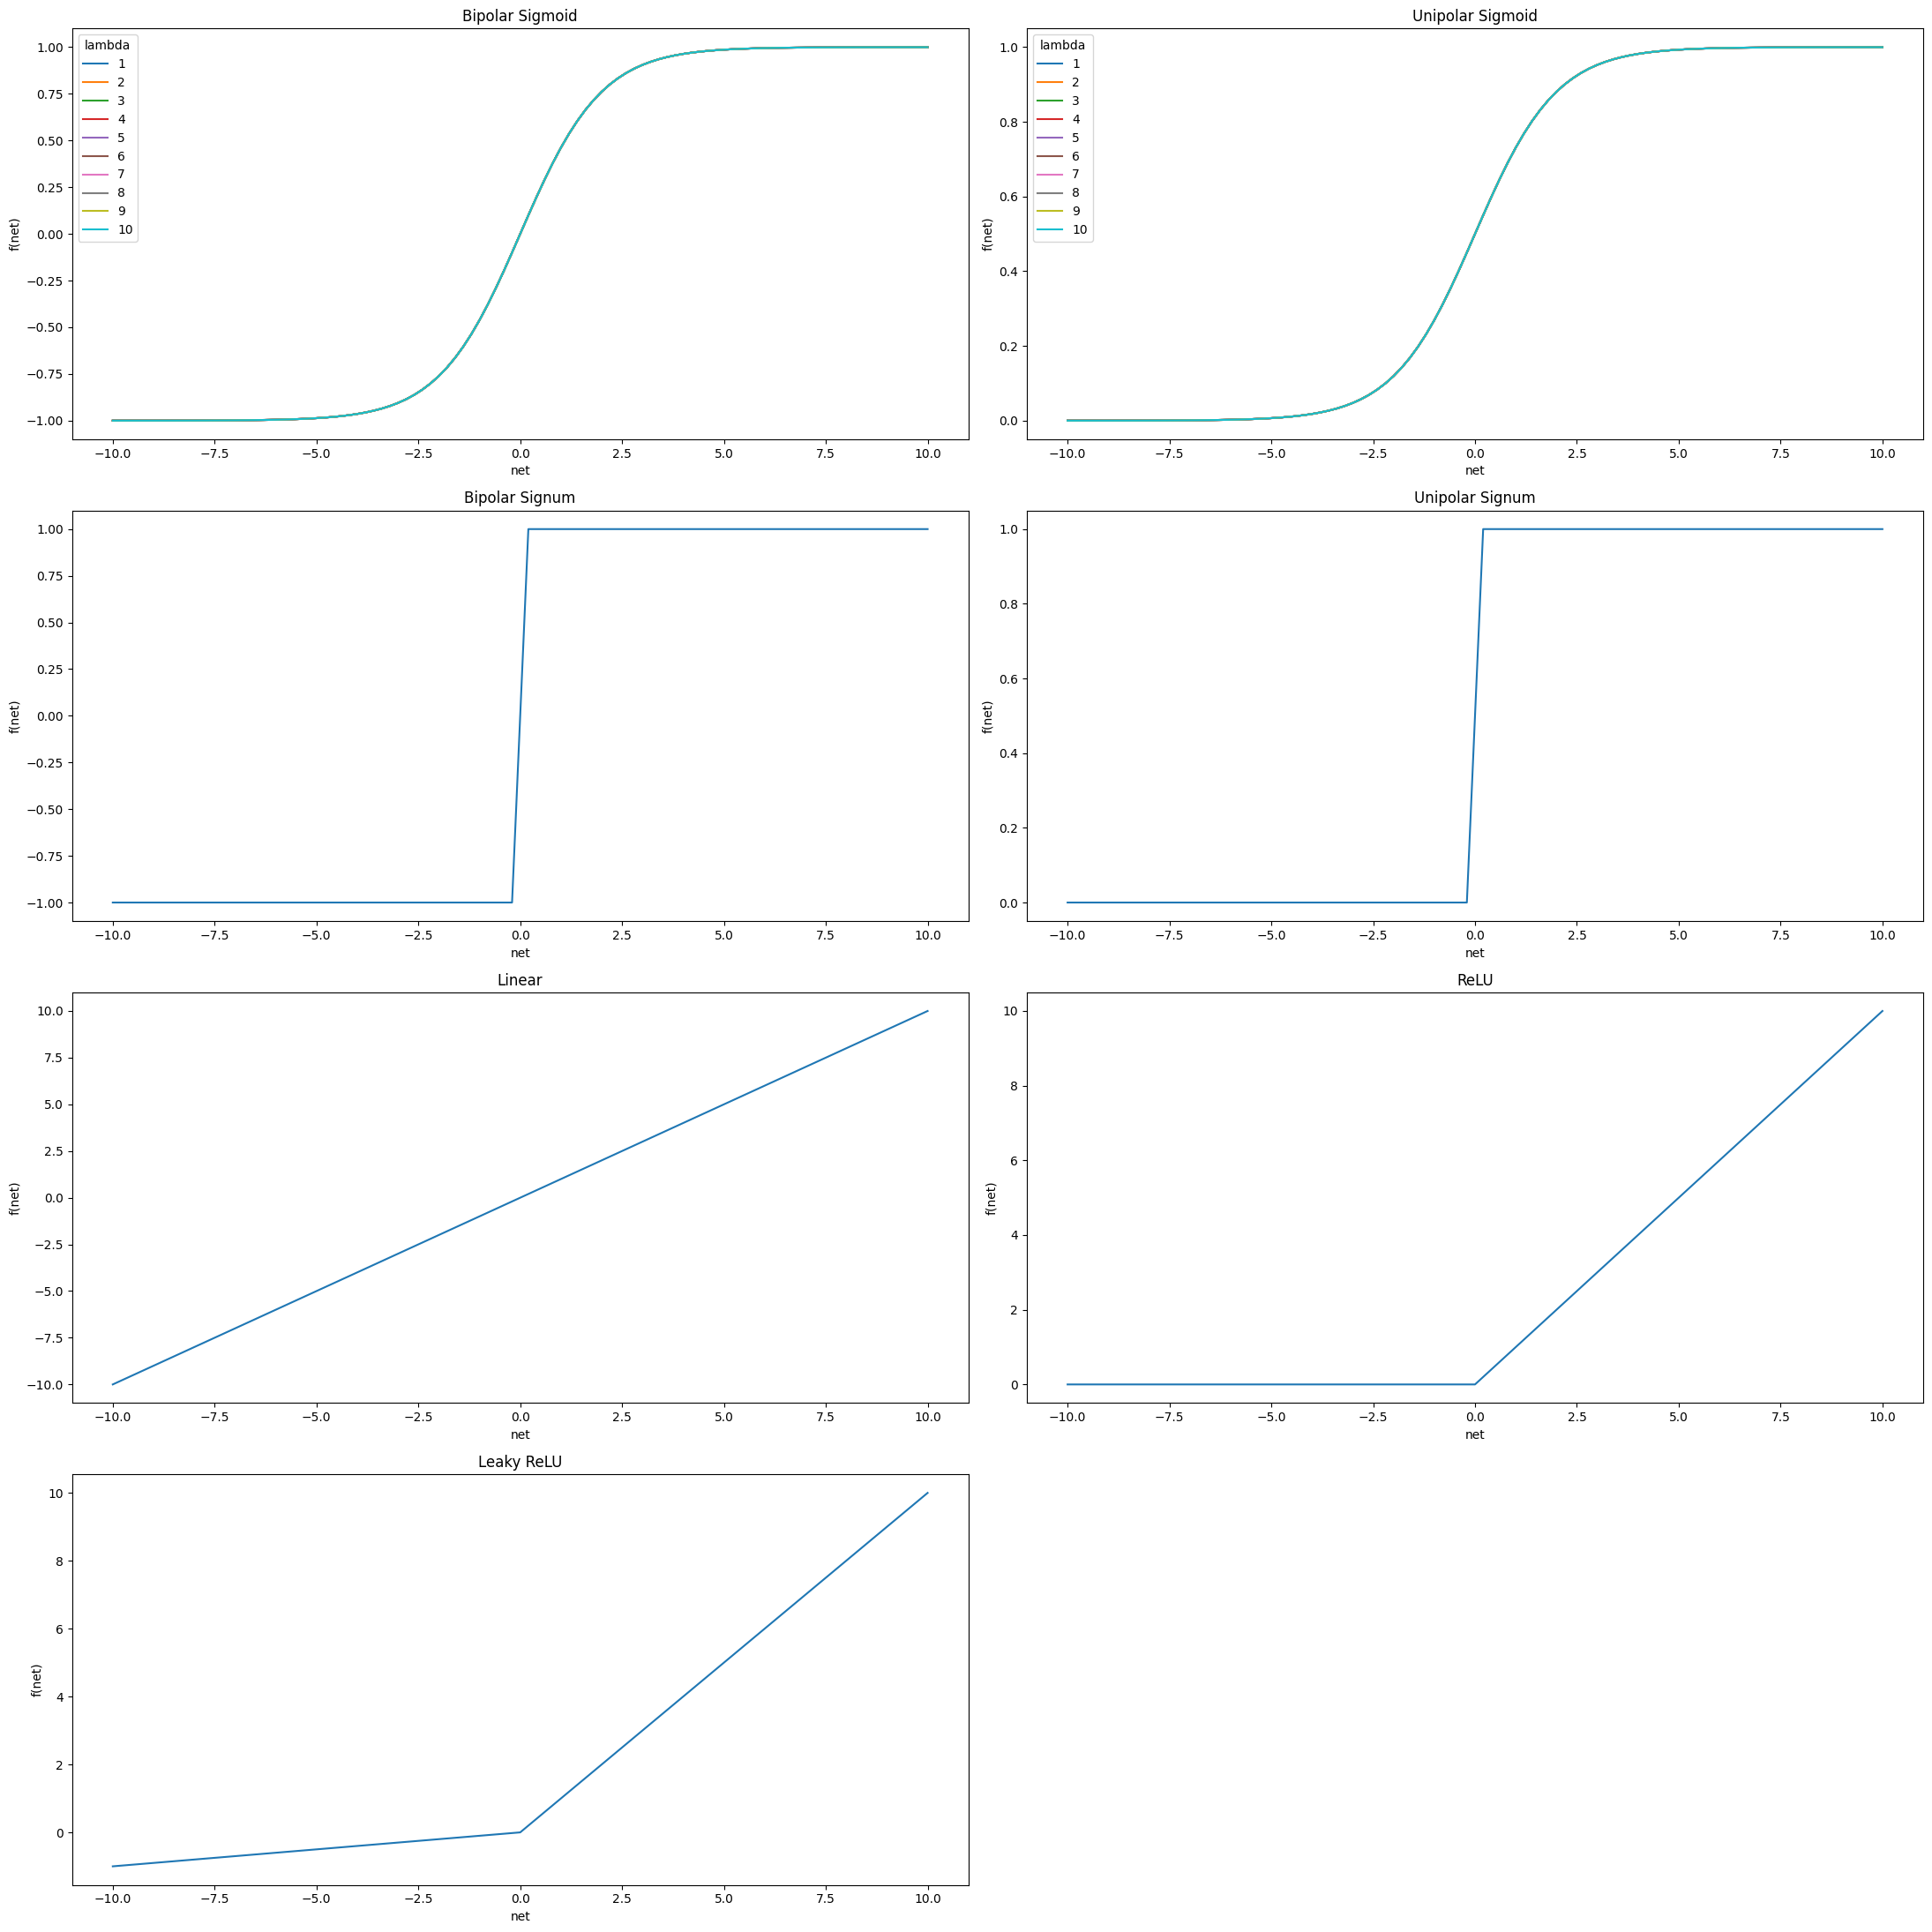

In [5]:
"""
Title: Visualization of Activation Functions in Neural Networks

Description:
This program plots different activation functions used in neural networks:
- Bipolar Sigmoid
- Unipolar Sigmoid
- Bipolar Signum
- Unipolar Signum
- Linear Function
- ReLU
- Leaky ReLU

These functions are commonly used to introduce non-linearity in neural networks.
"""

import numpy as np
import matplotlib.pyplot as plt


# ---------------------- INPUT RANGE ----------------------
net = np.linspace(-10, 10, 101)


# ---------------------- BIPOLAR SIGMOID ----------------------
def bipolar_sigmoid(net, l):
    """
    Bipolar Sigmoid Activation Function
    Range: [-1, 1]
    """
    return (2 / (1 + np.exp(-net))) - 1


plt.figure(figsize=(22, 22))

plt.subplot(4, 2, 1)
for l in range(1, 11):
    x = bipolar_sigmoid(net, l)
    plt.plot(net, x, label=l)

plt.legend(title='lambda')
plt.title('Bipolar Sigmoid')
plt.xlabel('net')
plt.ylabel('f(net)')


# ---------------------- UNIPOLAR SIGMOID ----------------------
def unipolar_sigmoid(net, l):
    """
    Unipolar Sigmoid Activation Function
    Range: [0, 1]
    """
    return 1 / (1 + np.exp(-net))


plt.subplot(4, 2, 2)
for l in range(1, 11):
    x = unipolar_sigmoid(net, l)
    plt.plot(net, x, label=l)

plt.legend(title='lambda')
plt.title('Unipolar Sigmoid')
plt.xlabel('net')
plt.ylabel('f(net)')


# ---------------------- BIPOLAR SIGNUM ----------------------
def bipolar_signum(net):
    """
    Bipolar Step Function:
    -1 for net < 0
     1 for net > 0
    """
    return np.sign(net)


plt.subplot(4, 2, 3)
x = bipolar_signum(net)
plt.plot(net, x)
plt.title('Bipolar Signum')
plt.xlabel('net')
plt.ylabel('f(net)')


# ---------------------- UNIPOLAR SIGNUM ----------------------
def unipolar_signum(net):
    """
    Unipolar Step Function:
    0 for net < 0
    1 for net > 0
    """
    return (np.sign(net) + 1) / 2


plt.subplot(4, 2, 4)
x = unipolar_signum(net)
plt.plot(net, x)
plt.title('Unipolar Signum')
plt.xlabel('net')
plt.ylabel('f(net)')


# ---------------------- LINEAR FUNCTION ----------------------
def linear(net):
    """
    Linear Activation Function:
    f(net) = net
    """
    return net


plt.subplot(4, 2, 5)
x = linear(net)
plt.plot(net, x)
plt.title('Linear')
plt.xlabel('net')
plt.ylabel('f(net)')


# ---------------------- ReLU ----------------------
def relu_my(x):
    """
    ReLU Activation Function:
    f(x) = max(0, x)
    """
    f = np.zeros(len(x))

    for i in range(len(x)):
        if x[i] > 0:
            f[i] = x[i]
        else:
            f[i] = 0
    return f


net = np.linspace(-10, 10, 21)

plt.subplot(4, 2, 6)
x = relu_my(net)
plt.plot(net, x)
plt.title('ReLU')
plt.xlabel('net')
plt.ylabel('f(net)')


# ---------------------- LEAKY ReLU ----------------------
def relu_myl(x):
    """
    Leaky ReLU Activation Function:
    f(x) = x if x > 0 else 0.1x
    """
    f = np.zeros(len(x))

    for i in range(len(x)):
        if x[i] > 0:
            f[i] = x[i]
        else:
            f[i] = 0.1 * x[i]
    return f


net = np.linspace(-10, 10, 21)

plt.subplot(4, 2, 7)
x = relu_myl(net)
plt.plot(net, x)
plt.title('Leaky ReLU')
plt.xlabel('net')
plt.ylabel('f(net)')


# ---------------------- SHOW PLOT ----------------------
plt.tight_layout()
plt.show()

# Back Propagation

In [6]:
"""
Title: Multilayer Perceptron (MLP) Training using Backpropagation

Description:
This program implements a simple 2-layer neural network trained using
backpropagation with gradient descent.

- Activation function: Bipolar Sigmoid
- Loss function: Mean Squared Error
- Learning method: Backpropagation

Network structure:
Input layer → Hidden layer → Output layer
"""

import numpy as np


# ---------------------- INPUT DATA ----------------------
x1 = np.array([0, 0, 1])
x2 = np.array([0, 1, 1])
x3 = np.array([1, 0, 1])
x4 = np.array([1, 1, 1])

x = [x1, x2, x3, x4]


# ---------------------- TARGET OUTPUTS ----------------------
d = [0, 1, 1, 0]


# ---------------------- INITIAL WEIGHTS ----------------------
w = np.array([1, 1, -1])              # Hidden → Output weights
v = np.array([[1, -1, -1],            # Input → Hidden weights
              [1, -2, 1]])


# ---------------------- BIPOLAR SIGMOID FUNCTION ----------------------
def sigmoid(net):
    """
    Bipolar Sigmoid Activation Function:
    Output range: [-1, 1]
    """
    return (2 / (1 + np.exp(-net))) - 1


# ---------------------- LEARNING RATE ----------------------
n = 0.05


# ---------------------- TRAINING LOOP ----------------------
for j in range(10000):

    E = 0  # total error per epoch

    for i in range(4):

        # -------- Forward Pass --------
        net1 = np.dot(v, x[i])      # hidden layer input
        y1 = sigmoid(net1)           # hidden layer output

        y1 = np.append(y1, 1)        # bias term added

        net2 = np.dot(w, y1)         # output layer input
        o1 = sigmoid(net2)           # final output

        # -------- Error Calculation --------
        e = 0.5 * (d[i] - o1) ** 2
        E += e

        # -------- Backpropagation --------
        do = 0.5 * (d[i] - o1) * (1 - o1 ** 2)

        dy = 0.5 * w * do * (1 - y1 ** 2)
        dy = dy[:2]   # remove bias term influence

        # -------- Weight Updates --------
        w = w + n * do * y1
        v = v + n * (dy.reshape(2, 1)) * (x[i].reshape(1, 3))

    # -------- Stopping Condition --------
    if E < 0.01:
        break


# ---------------------- OUTPUT ----------------------
print('Required iterations:', j + 1)
print('Updated hidden-output weights (W):', w)
print('Updated input-hidden weights (V):', v)

Required iterations: 4494
Updated hidden-output weights (W): [ 2.951527   -2.97163033  3.96064113]
Updated input-hidden weights (V): [[ 3.0740777  -3.200431   -1.53326459]
 [ 3.06012978 -3.17927401  1.67173102]]


# Fuzzy logic

In [7]:
"""
Title: Fuzzy Set Operations and Verification of Set Properties (Python Implementation)

Description:
This program demonstrates basic fuzzy set theory operations including:
- Complement
- Union
- Intersection
- Difference
- Verification of set properties (De Morgan's laws, commutative, associative, distributive)

Operations are performed using membership values in the range [0, 1].
"""

import numpy as np


# ---------------------- UNIVERSAL SET ----------------------
x = np.array([[1, 2, 3, 4, 5]])
print('Universe:', x)


# ---------------------- FUZZY SET A ----------------------
a = np.array([[1, 2, 3, 4, 5]])
print('Set A:', a)

ua = np.array([[0, 1, 0.5, 0.3, 0.2]])   # Membership values of A
print('Membership of A:', ua)


# ---------------------- FUZZY SET V ----------------------
v = np.array([[1, 2, 3, 4, 5]])
print('Set V:', v)

uv = np.array([[0, 0.5, 0.7, 0.2, 0.4]])  # Membership values of V
print('Membership of V:', uv)


# ---------------------- COMPLEMENT ----------------------
print('\n--- COMPLEMENT ---')

uab = 1 - ua
print('Complement of A:', uab)

uav = 1 - uv
print('Complement of V:', uav)


# ---------------------- UNION ----------------------
print('\n--- UNION ---')

auv = np.maximum(ua, uv)
print('Union (A ∪ V):', auv)


# ---------------------- INTERSECTION ----------------------
print('\n--- INTERSECTION ---')

aiv = np.minimum(ua, uv)
print('Intersection (A ∩ V):', aiv)


# ---------------------- DE MORGAN’S LAW CHECK ----------------------
print('\n--- DE MORGAN CHECK ---')

dav1 = 1 - np.maximum(ua, uv)
print('(A ∪ V) complement:', dav1)

dav2 = np.minimum(uab, uav)
print('(A ∩ V) complement:', dav2)


# ---------------------- DIFFERENCE ----------------------
print('\n--- DIFFERENCE ---')

ubda = np.minimum(uv, uab)
print('A - V (fuzzy difference):', ubda)

uadb = np.minimum(ua, uav)
print('V - A (fuzzy difference):', uadb)


# ---------------------- ADDITIONAL SET OPERATIONS ----------------------
print('\n--- EXTRA OPERATIONS ---')

w = np.maximum(ua, uab)
print('Union of A and A complement:', w)

x = np.minimum(ua, uab)
print('Intersection of A and A complement:', x)


# ---------------------- ASSOCIATIVE PROPERTY ----------------------
print('\n--- ASSOCIATIVE PROPERTY ---')

y = np.maximum(ua, uv)
z = np.maximum(uv, ua)

if np.all(y == z):
    print('Associative Property of Union holds')
else:
    print('Associative Property of Union does not hold')


# ---------------------- INTERSECTION CHECK ----------------------
m = np.minimum(ua, uv)
n = np.minimum(ua, uv)

if np.all(m == n):
    print('Associative Property of Intersection holds')
else:
    print('Associative Property of Intersection does not hold')


# ---------------------- THIRD SET FOR PROPERTIES ----------------------
uz = np.array([[0.4, 0.2, 0.7, 1, 0.5]])


# ---------------------- COMMUTATIVE PROPERTY ----------------------
print('\n--- COMMUTATIVE PROPERTY ---')

i = np.maximum(ua, np.maximum(uv, uz))
j = np.maximum(np.maximum(ua, uv), uz)

if np.all(i == j):
    print('Commutative Property holds')
else:
    print('Commutative Property does not hold')


# ---------------------- DISTRIBUTIVE PROPERTY ----------------------
print('\n--- DISTRIBUTIVE PROPERTY ---')

k = np.maximum(ua, np.minimum(uv, uz))
l = np.minimum(np.maximum(ua, uv), np.maximum(ua, uz))

if np.all(k == l):
    print('Distributive Property holds')
else:
    print('Distributive Property does not hold')

Universe: [[1 2 3 4 5]]
Set A: [[1 2 3 4 5]]
Membership of A: [[0.  1.  0.5 0.3 0.2]]
Set V: [[1 2 3 4 5]]
Membership of V: [[0.  0.5 0.7 0.2 0.4]]

--- COMPLEMENT ---
Complement of A: [[1.  0.  0.5 0.7 0.8]]
Complement of V: [[1.  0.5 0.3 0.8 0.6]]

--- UNION ---
Union (A ∪ V): [[0.  1.  0.7 0.3 0.4]]

--- INTERSECTION ---
Intersection (A ∩ V): [[0.  0.5 0.5 0.2 0.2]]

--- DE MORGAN CHECK ---
(A ∪ V) complement: [[1.  0.  0.3 0.7 0.6]]
(A ∩ V) complement: [[1.  0.  0.3 0.7 0.6]]

--- DIFFERENCE ---
A - V (fuzzy difference): [[0.  0.  0.5 0.2 0.4]]
V - A (fuzzy difference): [[0.  0.5 0.3 0.3 0.2]]

--- EXTRA OPERATIONS ---
Union of A and A complement: [[1.  1.  0.5 0.7 0.8]]
Intersection of A and A complement: [[0.  0.  0.5 0.3 0.2]]

--- ASSOCIATIVE PROPERTY ---
Associative Property of Union holds
Associative Property of Intersection holds

--- COMMUTATIVE PROPERTY ---
Commutative Property holds

--- DISTRIBUTIVE PROPERTY ---
Distributive Property holds


# Bidirectional Associative Memory (BAM)

In [8]:
"""
Title: Bidirectional Associative Memory (BAM) Neural Network Implementation

Description:
This program implements a Bidirectional Associative Memory (BAM),
a type of recurrent neural network used for pattern association.

It stores associations between two pattern sets (A and B) and allows:
- Forward recall (A → B)
- Backward recall (B → A)

Learning is done using Hebbian outer product rule:
    W = Σ (Aᵀ × B)
"""

print("BAM\n")

import numpy as np


# ---------------------- RANDOM SEED ----------------------
np.random.seed(2)


# ---------------------- SIGNUM FUNCTION ----------------------
def signum(net):
    """
    Bipolar signum activation function:
    Converts values to:
    1  if net > 0
   -1  otherwise
    """
    shape = np.shape(net)
    z = np.zeros(shape)

    for i in range(shape[0]):
        for j in range(shape[1]):
            if net[i][j] > 0:
                z[i][j] = 1
            else:
                z[i][j] = -1
    return z


# ---------------------- TRAINING PATTERNS ----------------------
a1 = np.array([[1, 1, -1, -1, 1]])
a2 = np.array([[-1, 1, 1, -1, -1]])
a3 = np.array([[1, 1, -1, 1, -1]])

b1 = np.array([[-1, -1, 1, 1, -1, 1, -1]])
b2 = np.array([[-1, -1, -1, -1, -1, -1, -1]])
b3 = np.array([[1, 1, 1, -1, -1, -1, -1]])


# ---------------------- RANDOM PATTERN ----------------------
a4 = np.array([np.random.randint(-1, 2, 5)])
a4[a4 < 0.5] = -1

b4 = np.array([np.random.randint(-1, 2, 7)])
b4[b4 < 0.5] = -1


# ---------------------- WEIGHT MATRIX (HEBBIAN OUTER PRODUCT) ----------------------
W = (np.outer(a1, b1) +
     np.outer(a2, b2) +
     np.outer(a3, b3) +
     np.outer(a4, b4))

print('Final Weights are:\n', W)


# ---------------------- FORWARD & BACKWARD RECALL ----------------------

# Pattern 1
B1 = signum(np.dot(a1, W))
A1 = signum(np.dot(B1, W.T))

# Pattern 2
B2 = signum(np.dot(a2, W))
A2 = signum(np.dot(B2, W.T))

# Pattern 3
B3 = signum(np.dot(a3, W))
A3 = signum(np.dot(B3, W.T))

# Pattern 4
B4 = signum(np.dot(a4, W))
A4 = signum(np.dot(B4, W.T))


# ---------------------- ERROR CHECKING ----------------------
print('\nError Analysis:\n')

print("Pattern 1 Error:\n", A1 - a1)
print("Pattern 2 Error:\n", A2 - a2)
print("Pattern 3 Error:\n", A3 - a3)
print("Pattern 4 Error:\n", A4 - a4)

BAM

Final Weights are:
 [[ 2  0  4  2 -2  2  0]
 [ 0 -2  2  0 -4  0 -2]
 [ 0 -2 -2  0  0  0  2]
 [ 2  4  0 -2  2 -2  0]
 [-2  0  0  2  2  2  0]]

Error Analysis:

Pattern 1 Error:
 [[0. 0. 0. 0. 0.]]
Pattern 2 Error:
 [[0. 0. 0. 0. 0.]]
Pattern 3 Error:
 [[0. 0. 0. 0. 0.]]
Pattern 4 Error:
 [[ 0.  0.  0.  0. -2.]]
